# Feature-count sweep (cross-validated, by original variable)

Question: is 44 the right number of features? 44 came from the PCA recipe (top 10 components x top 5 loadings), not from a performance criterion. This notebook sweeps the number of **original survey variables** `k`.

Design:

1. Same household-grouped 80/20 split as `ALE_leakage_audit.ipynb` (`random_state=42`). The test households are not touched until the final step.
2. On the training households only, 5-fold `GroupKFold` by `HHID`. **Inside each fold** a selection model is fit on the fold-train rows, original variables are ranked by summed gain over their dummies, and the top-k variables (all of their dummies) are refit and scored on the held-out fold. Selection never sees the held-out fold.
3. `AGE` is forced into every set (it counts toward k), `READ_IND_F3` is excluded as a proxy, and Form 2 derived columns stay excluded, as in the leakage audit.
4. k is chosen by the one-standard-error rule on weighted ROC-AUC: the smallest k whose mean CV AUC is within one SE of the best mean.
5. Stability: how often each variable is in the top k across folds.
6. Final: rank once on all training rows, take the chosen k, evaluate once on the test households.

Outputs are written next to this notebook in `02_xgboost_xai/` (prefix `sweep_`).

In [1]:
import gc, os, re, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
N_FOLDS = 5
K_GRID = [5, 8, 10, 15, 20, 25, 30, 40, 50, 60, 75, 100, 125, None]   # None = all variables
N_TREES_SELECT = 200   # same as the leakage audit
N_TREES_FINAL = 300

DATA = '../data/PHL-PSA-FLEMMS-2024-V1-PUF/'
DATA2 = '../data/PHL-PSA-FLEMMS-2024-V2-PUF/'
MEMBER_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - MEMBER.CSV'
RTF1_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - RTF1.CSV'
RTF2_FILE = DATA + 'FLEMMS PUF 2024 Volume1 - RTF2.CSV'
RTF3_FILE = DATA2 + 'FLEMMS PUF 2024 Volume2 - RTF3.CSV'
CV_FILE = 'sweep_cv_results.csv'   # appended after every (fold, k) so a killed run can resume
os.makedirs('ale_figures', exist_ok=True)


## 1. Load, merge, filter (same code as the leakage audit)

In [2]:
overlap_cols = ['REG', 'PRV', 'MUN', 'BGY', 'URBANITY', 'REG2']

def drop_overlaps(df, keys):
    return df.drop(columns=[c for c in overlap_cols if c in df.columns and c not in keys])

m = pd.read_csv(MEMBER_FILE)
r1 = drop_overlaps(pd.read_csv(RTF1_FILE), ['HHID'])
r2 = pd.read_csv(RTF2_FILE).rename(columns={'LNO_F2': 'LNO'})
r3 = pd.read_csv(RTF3_FILE).rename(columns={'LNO_F3': 'LNO'})
r2, r3 = drop_overlaps(r2, ['HHID', 'LNO']), drop_overlaps(r3, ['HHID', 'LNO'])

# merge-key uniqueness (Notebook_Verification_TODO item 1)
assert not r1['HHID'].duplicated().any()
assert not r2.duplicated(['HHID', 'LNO']).any()
assert not r3.duplicated(['HHID', 'LNO']).any()

df = (m.merge(r1, on='HHID', how='left')
        .merge(r2, on=['HHID', 'LNO'], how='left')
        .merge(r3, on=['HHID', 'LNO'], how='left'))
assert len(df) == len(m), 'merge fan-out'
df = df[(df['AGE'] >= 10) & (df['AGE'] <= 64)].copy()
del m, r1, r2, r3; gc.collect()

df['FLITERATE'] = pd.to_numeric(df['FLITERATE'], errors='coerce')
df = df[df['FLITERATE'].notna() & df['RESP_RFACT_F2'].notna()].reset_index(drop=True)
y = (df['FLITERATE'] == 2).astype(int).to_numpy()   # 1 = functionally illiterate
w = df['RESP_RFACT_F2'].to_numpy(dtype=float)
groups = df['HHID'].to_numpy()
print('analysis rows:', len(df), '| weighted prevalence:', round(np.average(y, weights=w), 4),
      '| households:', len(np.unique(groups)))

analysis rows: 468643 | weighted prevalence: 0.2921 | households: 163655


## 2. Preprocess, tracking which dummies belong to which original variable

Same rules as the leakage audit (exclusion list, `Not_Applicable` imputation, more than 50 levels and constant columns dropped, `drop_first=True`). Each variable is encoded on its own so the dummy-to-variable map is exact. `READ_IND_F3` is excluded up front.

In [3]:
BASE_EXCLUDE = [
    'HHID', 'LNO', 'REG', 'PRV', 'MUN', 'BGY', 'URBANITY', 'REG2',
    'PSU', 'PSU_MEM', 'PSU_F1', 'PSU_F2', 'PSU_F3',
    'MEM_RFACT', 'HH_RFACT', 'RESP_RFACT_F2', 'RESP_RFACT_F3',
    'RESULT_CODE_F2', 'RESP_AGREE_F2', 'READ_IND_F2',
    'READING', 'WRITING', 'COMPUTE', 'COMPRE',
    'READING59', 'WRITING59', 'COMPUTE59',
    'LLEVEL59', 'LLEVEL10OVER', 'LLEVEL5OVER', 'FLLEVEL', 'FLLEVEL_0',
    'BASIC_NUM', 'BASIC_LIT', 'BLITERATE', 'BLITERATE_1', 'BLITERATE_2',
    'RESULT_CODE_F3', 'RESP_AGREE_F3',
    'AGE_F2', 'AGE_F3', 'SEX_F2', 'SEX_F3', 'REL_F2', 'REL_F3',
    'HGC_GRADE_F2', 'HGC_GRADE_F3', 'FLITERATE']

EXTRA_EXCLUDE = ['READ_IND_F3', 'MOTHER_LNO', 'FATHER_LNO']   # F3: outcome proxy (ALE_LEAKAGE_FINDINGS.md section 2); *_LNO: parent roster line numbers, 16-17 level IDs with no policy reading (dropped 2026-11-01)
feat = df.drop(columns=[c for c in BASE_EXCLUDE + EXTRA_EXCLUDE if c in df.columns])

def as_cat(s):
    if pd.api.types.is_numeric_dtype(s):
        nn = s.dropna()
        if len(nn) and (nn % 1 == 0).all():
            s = s.astype('Int64')
    return s.astype('string').fillna('Not_Applicable')

blocks, var_of = [], {}
blocks.append(feat['AGE'].fillna(feat['AGE'].median()).astype(float).rename('AGE').to_frame())
var_of['AGE'] = 'AGE'
for c in feat.columns:
    if c == 'AGE': continue
    nu = feat[c].nunique(dropna=False)
    if nu > 50 or nu <= 1: continue
    d = pd.get_dummies(as_cat(feat[c]), prefix=c, drop_first=True, dtype=np.uint8)
    blocks.append(d)
    var_of.update({col: c for col in d.columns})
X = pd.concat(blocks, axis=1)
del feat, blocks; gc.collect()
var_of = pd.Series(var_of)
VARS = list(dict.fromkeys(var_of.values))
print('encoded matrix:', X.shape, '| original variables:', len(VARS))
assert list(var_of.index) == list(X.columns)


encoded matrix: (468643, 703) | original variables: 148


## 3. Grouped split (identical to the leakage audit) and helper functions

In [4]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
tr_idx, te_idx = next(gss.split(X, y, groups))
Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
ytr, yte, wtr, wte, gtr = y[tr_idx], y[te_idx], w[tr_idx], w[te_idx], groups[tr_idx]
assert not set(groups[tr_idx]) & set(groups[te_idx])
del X; gc.collect()
print(f'train {len(tr_idx):,} | test {len(te_idx):,}')

def make_model(n_trees, yy):
    spw = (yy == 0).sum() / max((yy == 1).sum(), 1)
    return XGBClassifier(n_estimators=n_trees, learning_rate=0.05, max_depth=6,
                         scale_pos_weight=spw, tree_method='hist',
                         random_state=SEED, eval_metric='auc', n_jobs=-1)

def rank_variables(Xa, ya, wa):
    """Selection model on the given rows only. Gain summed over each variable's dummies; AGE is moved to the front."""
    m = make_model(N_TREES_SELECT, ya).fit(Xa, ya, sample_weight=wa)
    g = pd.Series(m.feature_importances_, index=Xa.columns).groupby(var_of).sum()
    order = g.sort_values(ascending=False).index.tolist()
    return ['AGE'] + [v for v in order if v != 'AGE'], g

def cols_of(vs):
    s = set(vs)
    return [c for c, v in var_of.items() if v in s]

def fit_score(Xa, ya, wa, Xb, yb, wb, cols):
    m = make_model(N_TREES_FINAL, ya).fit(Xa[cols], ya, sample_weight=wa)
    p = m.predict_proba(Xb[cols])[:, 1]
    return (roc_auc_score(yb, p, sample_weight=wb), average_precision_score(yb, p, sample_weight=wb),
            roc_auc_score(yb, p))


train 374,921 | test 93,722


## 4. Cross-validated sweep (training households only)

Resumable: finished (fold, k) pairs are read from `sweep_cv_results.csv` and skipped. The ranking for each fold is stored in `sweep_fold_rankings.csv`.

In [5]:
done = pd.read_csv(CV_FILE) if os.path.exists(CV_FILE) else pd.DataFrame(
    columns=['fold', 'k', 'n_dummies', 'roc_auc_w', 'pr_auc_w', 'roc_auc_unw'])
RANK_FILE = 'sweep_fold_rankings.csv'
ranks = pd.read_csv(RANK_FILE) if os.path.exists(RANK_FILE) else pd.DataFrame(columns=['fold', 'rank', 'variable'])
ks = [len(VARS) if k is None else k for k in K_GRID]

for f, (a, b) in enumerate(GroupKFold(n_splits=N_FOLDS).split(Xtr, ytr, gtr)):
    todo = [k for k in ks if not ((done.fold == f) & (done.k == k)).any()]
    if not todo: continue
    Xa, Xb = Xtr.iloc[a], Xtr.iloc[b]
    ya, yb, wa, wb = ytr[a], ytr[b], wtr[a], wtr[b]
    assert not set(gtr[a]) & set(gtr[b])
    if not (ranks.fold == f).any():
        order, _ = rank_variables(Xa, ya, wa)
        ranks = pd.concat([ranks, pd.DataFrame({'fold': f, 'rank': range(1, len(order) + 1), 'variable': order})])
        ranks.to_csv(RANK_FILE, index=False)
    order = ranks[ranks.fold == f].sort_values('rank')['variable'].tolist()
    for k in todo:
        cols = cols_of(order[:k])
        auc, pr, auc_u = fit_score(Xa, ya, wa, Xb, yb, wb, cols)
        done = pd.concat([done, pd.DataFrame([{'fold': f, 'k': k, 'n_dummies': len(cols),
                                               'roc_auc_w': auc, 'pr_auc_w': pr, 'roc_auc_unw': auc_u}])])
        done.to_csv(CV_FILE, index=False)
        print(f'fold {f} k={k:>3} dummies={len(cols):>3} AUC={auc:.4f} PR={pr:.4f}')
    del Xa, Xb; gc.collect()


fold 0 k=  5 dummies= 60 AUC=0.6761 PR=0.4723


fold 0 k=  8 dummies=105 AUC=0.6839 PR=0.4804


fold 0 k= 10 dummies=120 AUC=0.6875 PR=0.4869


fold 0 k= 15 dummies=179 AUC=0.6937 PR=0.4970


fold 0 k= 20 dummies=250 AUC=0.6955 PR=0.4977


fold 0 k= 25 dummies=293 AUC=0.6974 PR=0.5000


... (60 outputs left out)

fold 4 k= 75 dummies=570 AUC=0.7075 PR=0.5120


fold 4 k=100 dummies=622 AUC=0.7099 PR=0.5141


fold 4 k=125 dummies=675 AUC=0.7102 PR=0.5147


fold 4 k=148 dummies=703 AUC=0.7104 PR=0.5153


## 5. Choosing k: one-standard-error rule

In [6]:
cv = pd.read_csv(CV_FILE)
s = cv.groupby('k').agg(n_dummies=('n_dummies', 'mean'),
                        auc_mean=('roc_auc_w', 'mean'), auc_sd=('roc_auc_w', 'std'),
                        pr_mean=('pr_auc_w', 'mean'), pr_sd=('pr_auc_w', 'std'),
                        n_folds=('fold', 'nunique'))
s['auc_se'] = s['auc_sd'] / np.sqrt(s['n_folds']); s['pr_se'] = s['pr_sd'] / np.sqrt(s['n_folds'])
best = s['auc_mean'].idxmax()
thresh = s.loc[best, 'auc_mean'] - s.loc[best, 'auc_se']
k_star = int(s.index[s['auc_mean'] >= thresh].min())
s['within_1se'] = s['auc_mean'] >= thresh
s.round(4).to_csv('sweep_cv_summary.csv')
print(f'best mean AUC at k={best} ({s.loc[best, "auc_mean"]:.4f}, SE {s.loc[best, "auc_se"]:.4f}); '
      f'threshold {thresh:.4f}; chosen k* = {k_star}')
s.round(4)


best mean AUC at k=148 (0.7097, SE 0.0009); threshold 0.7087; chosen k* = 100


,n_dummies,auc_mean,auc_sd,pr_mean,pr_sd,n_folds,auc_se,pr_se,within_1se
k,,,,,,,,,
5,60.0,0.6804,0.0033,0.4796,0.0061,5,0.0015,0.0027,False
8,93.2,0.6858,0.0022,0.4864,0.0050,5,0.0010,0.0023,False
10,120.4,0.6887,0.0034,0.4916,0.0063,5,0.0015,0.0028,False
15,179.4,0.6942,0.0016,0.5008,0.0049,5,0.0007,0.0022,False
20,237.4,0.6971,0.0020,0.5035,0.0049,5,0.0009,0.0022,False
25,293.8,0.6993,0.0014,0.5067,0.0061,5,0.0006,0.0027,False
30,321.6,0.7011,0.0017,0.5098,0.0054,5,0.0008,0.0024,False
40,384.6,0.7036,0.0015,0.5122,0.0045,5,0.0006,0.0020,False
50,436.8,0.7044,0.0019,0.5130,0.0056,5,0.0009,0.0025,False


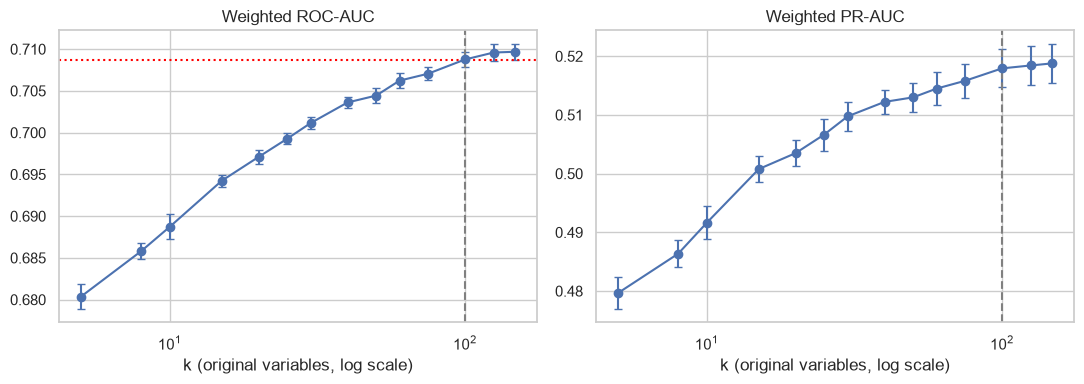

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a_, (m_, e_, t_) in zip(ax, [('auc_mean', 'auc_se', 'Weighted ROC-AUC'), ('pr_mean', 'pr_se', 'Weighted PR-AUC')]):
    a_.errorbar(s.index, s[m_], yerr=s[e_], marker='o', capsize=3)
    a_.axvline(k_star, ls='--', c='grey'); a_.set_xscale('log'); a_.set_xlabel('k (original variables, log scale)'); a_.set_title(t_)
ax[0].axhline(thresh, ls=':', c='red')
plt.tight_layout(); plt.savefig('ale_figures/sweep_cv_curve.png', dpi=150); plt.show()


## 6. Stability of the ranking across folds

In [8]:
ranks = pd.read_csv(RANK_FILE)
top = {f: ranks[ranks.fold == f].sort_values('rank')['variable'].tolist() for f in sorted(ranks.fold.unique())}
rows = []
for k in ks:
    sets = [set(v[:k]) for v in top.values()]
    jac = np.mean([len(a & b) / len(a | b) for a, b in itertools.combinations(sets, 2)])
    rows.append({'k': k, 'mean_pairwise_jaccard': jac, 'in_all_folds': len(set.intersection(*sets)),
                 'in_any_fold': len(set.union(*sets))})
stab = pd.DataFrame(rows); stab.round(3).to_csv('sweep_stability_by_k.csv', index=False)
freq = pd.Series({v: sum(v in t[:k_star] for t in top.values()) for v in set(itertools.chain(*[t[:k_star] for t in top.values()]))})
freq = freq.sort_values(ascending=False).rename('folds_in_top_k_star').to_frame()
freq.to_csv('sweep_variable_frequency_at_kstar.csv')
print(stab.round(3).to_string(index=False)); print(f'\nVariable frequency at k*={k_star}:'); print(freq.to_string())


  k  mean_pairwise_jaccard  in_all_folds  in_any_fold
  5                  0.733             4            7
  8                  0.782             6           10
 10                  0.858             8           12
 15                  0.810            12           19
 20                  0.774            15           25
 25                  0.861            22           30
 30                  0.792            24           38
 40                  0.771            31           53
 50                  0.803            40           61
 60                  0.858            51           70
 75                  0.909            67           82
100                  0.868            85          113
125                  0.886           109          139
148                  1.000           148          148

Variable frequency at k*=100:
                     folds_in_top_k_star
MODETRVL2                              5
DSKILL_SAFE2                           5
NATT_REASON                         

## 7. Final model: rank on all training rows, chosen k*, evaluate once on the test households

In [9]:
order_full, gain_full = rank_variables(Xtr, ytr, wtr)
final_vars = order_full[:k_star]
cols = cols_of(final_vars)
auc, pr, auc_u = fit_score(Xtr, ytr, wtr, Xte, yte, wte, cols)
print(f'k*={k_star} | {len(cols)} dummies | test weighted ROC-AUC {auc:.4f} | PR-AUC {pr:.4f} | unweighted AUC {auc_u:.4f}')
ref = pd.read_csv('primary_model_metrics.csv'); print('\nreference (45-feature primary model):'); print(ref.round(4).to_string(index=False))
pd.DataFrame({'rank': range(1, len(final_vars) + 1), 'variable': final_vars,
              'summed_gain': gain_full.reindex(final_vars).values,
              'n_dummies': [len(cols_of([v])) for v in final_vars]}).to_csv('sweep_selected_variables.csv', index=False)
pd.DataFrame({'Feature_Name': cols, 'Variable': var_of[cols].values}).to_csv('sweep_selected_dummies.csv', index=False)
pd.DataFrame([{'k_star': k_star, 'n_dummies': len(cols), 'test_roc_auc_w': auc, 'test_pr_auc_w': pr,
               'test_roc_auc_unw': auc_u}]).to_csv('sweep_final_metrics.csv', index=False)


k*=100 | 628 dummies | test weighted ROC-AUC 0.7114 | PR-AUC 0.5176 | unweighted AUC 0.7170

reference (45-feature primary model):
 roc_auc_weighted  pr_auc_weighted  roc_auc_unweighted
           0.7019           0.5051              0.7082
